# Loss curves: predeclared single models

Two hidden layers of width 256, seed 42, for Kryptonite-20/30/40. Read existing locked training histories only; no fitting or test scoring. Training and validation BCE are evaluated over the complete respective partition using epoch-end weights and exclude the weight penalty. Checkpoints were selected by **validation accuracy**, with loss breaking ties, not by minimum validation loss. The dotted line marks the selected checkpoint; the dashed line marks early stopping. Plot directly with `plt.show()`; no PDF export.

Matplotlib is building the font cache; this may take a moment.


Kryptonite-20: selected epoch 39, stopped at 59
Kryptonite-30: selected epoch 34, stopped at 54
Kryptonite-40: selected epoch 18, stopped at 38


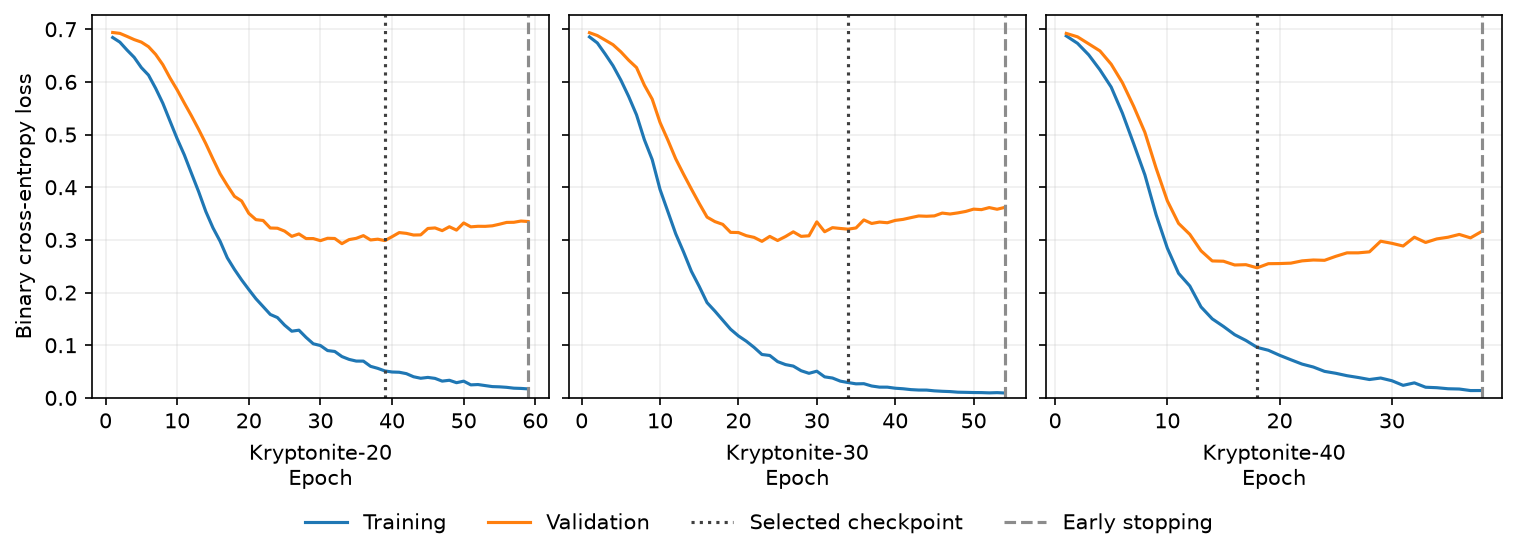

In [1]:
from pathlib import Path
import csv, hashlib, json, sys
import numpy as np
import matplotlib.pyplot as plt
root=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'common.py').is_file())
assert Path(sys.prefix).resolve()==(root/'.venv').resolve()
lock_path=root/'member_c/configs/p3_lock.json'
assert hashlib.sha256(lock_path.read_bytes()).hexdigest()=='096ae5d7e7ca0493804aff0cc5b1f8b7c89314a6276f1f86cd66bdd4e62fcfba'
lock=json.loads(lock_path.read_text())
models=sorted([m for m in lock['models'] if m['width']==256 and m['seed']==42],key=lambda m:int(m['dataset']))
assert [m['dataset'] for m in models]==['20','30','40']
plt.rcParams.update({'text.usetex':False,'font.family':'DejaVu Sans','font.size':10,'figure.dpi':150})
fig,axes=plt.subplots(1,3,figsize=(10,3.6),sharey=True,layout='constrained')
for ax,m in zip(axes,models):
    run=(root/m['checkpoint']).parent
    for name in ['history.csv','summary.json']:
        p=run/name
        assert hashlib.sha256(p.read_bytes()).hexdigest()==lock['protected_sha256'][str(p.relative_to(root))]
    summary=json.loads((run/'summary.json').read_text())
    with (run/'history.csv').open() as f: rows=list(csv.DictReader(f))
    epochs=np.array([int(r['epoch']) for r in rows])
    assert summary['best_epoch']==m['best_epoch'] and len(rows)==summary['epochs_run']
    ax.plot(epochs,[float(r['train_loss']) for r in rows],color='tab:blue',label='Training')
    ax.plot(epochs,[float(r['validation_loss']) for r in rows],color='tab:orange',label='Validation')
    ax.axvline(m['best_epoch'],color='0.25',ls=':',label='Selected checkpoint')
    ax.axvline(summary['epochs_run'],color='0.55',ls='--',label='Early stopping')
    ax.set(xlabel=f"Kryptonite-{m['dataset']}\nEpoch",ylim=(0,None))
    ax.grid(alpha=.2)
    print(f"Kryptonite-{m['dataset']}: selected epoch {m['best_epoch']}, stopped at {summary['epochs_run']}")
axes[0].set_ylabel('Binary cross-entropy loss')
handles,labels=axes[0].get_legend_handles_labels()
fig.legend(handles,labels,loc='outside lower center',ncol=4,frameon=False)
plt.show()